<a href="https://colab.research.google.com/github/szlot/myrepo/blob/main/Window_HOU_3_0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -U ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 4.1 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

print("Ultralytics installed successfully")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics installed successfully


In [ ]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")

In [ ]:
from pathlib import Path
from urllib.parse import urlparse
import requests

# Direct URL to the video
video_url = "https://sporty-clips.mlb.com/bkJva2RfWGxnR0RBeGJDMWM9X1Z3ZFlVbHdEQTFRQURBRlRVd0FBQ0FWVkFGaFFBZ01BQ2djTUF3cFRCRklCQVZjRg==.mp4"

# Create output directory
output_dir = Path("videos")
output_dir.mkdir(exist_ok=True)

# Extract filename directly from the URL or set a custom name
filename = Path(urlparse(video_url).path).name
video_path = output_dir / filename

# Stream and save the video
with requests.get(video_url, stream=True, timeout=60) as response:
    response.raise_for_status()
    with video_path.open("wb") as f:
        # 1 MB chunks
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)

print(f"Saved: {video_path}")
print(f"Size: {video_path.stat().st_size / 1_000_000:.1f} MB")

Saved: videos/bkJva2RfWGxnR0RBeGJDMWM9X1Z3ZFlVbHdEQTFRQURBRlRVd0FBQ0FWVkFGaFFBZ01BQ2djTUF3cFRCRklCQVZjRg==.mp4
Size: 7.8 MB


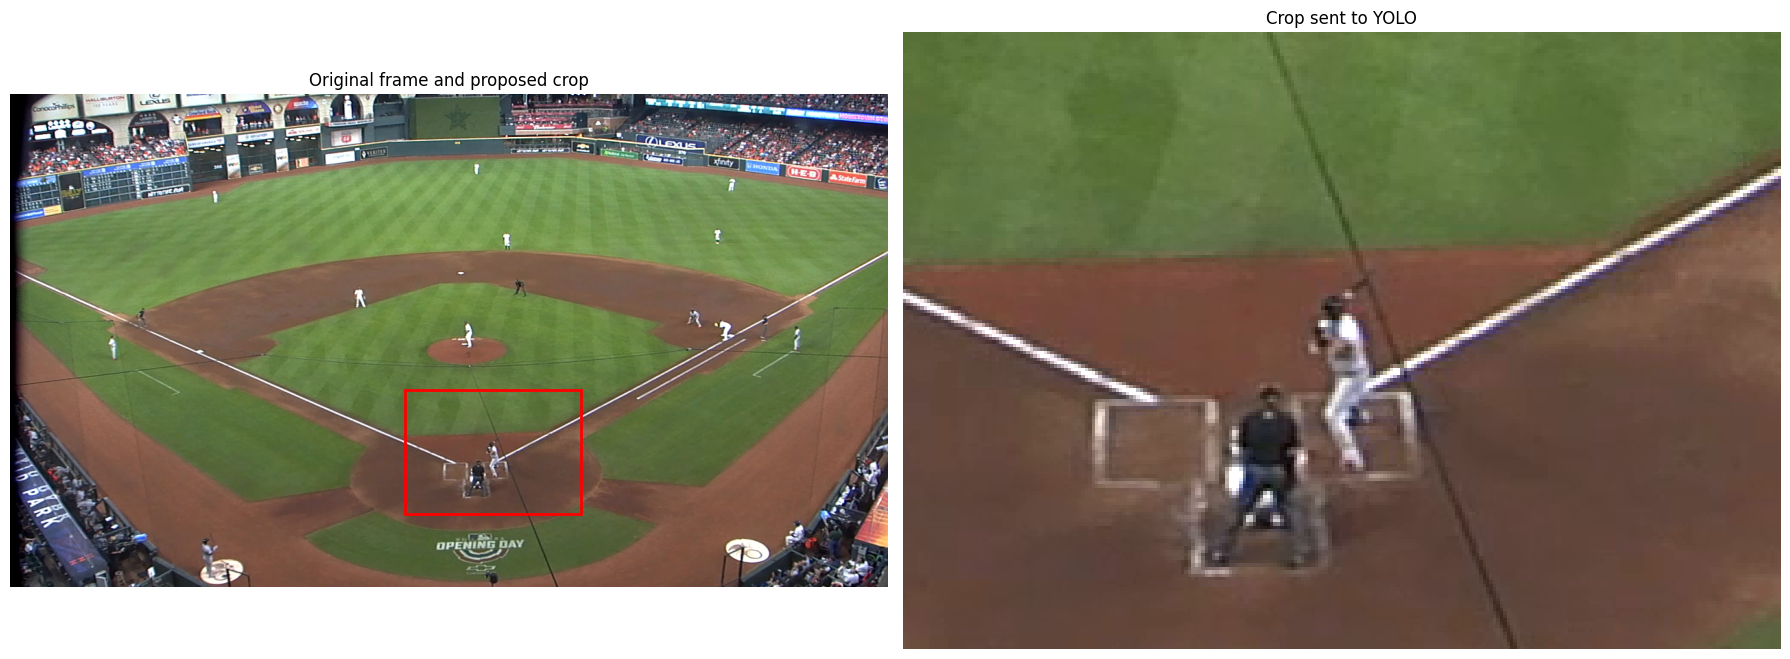

In [ ]:
# Display a frame and your proposed crop
# Start with a broad left-side region. The red rectangle shows exactly what you’re sending to YOLO. Adjust the four fractions until it contains the coach and room for extended arms.

import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

time_seconds = 2.0

cap = cv2.VideoCapture(str(video_path))
if not cap.isOpened():
    raise RuntimeError("Video could not be opened.")

cap.set(cv2.CAP_PROP_POS_MSEC, time_seconds * 1000)
ok, frame = cap.read()
cap.release()

if not ok:
    raise RuntimeError("Could not read frame. Try time_seconds = 0.")

# Starting region only — adjust after inspecting the image.
# Fractions: left, top, right, bottom
crop_region = (0.45, 0.6, 0.65, 0.85)

left, top, right, bottom = crop_region
assert 0 <= left < right <= 1
assert 0 <= top < bottom <= 1

height, width = frame.shape[:2]
x1, y1 = int(left * width), int(top * height)
x2, y2 = int(right * width), int(bottom * height)

roi = frame[y1:y2, x1:x2].copy()

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

axes[0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
axes[0].add_patch(Rectangle(
    (x1, y1), x2 - x1, y2 - y1,
    fill=False, edgecolor="red", linewidth=2
))
axes[0].set_title("Original frame and proposed crop")

axes[1].imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))
axes[1].set_title("Crop sent to YOLO")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

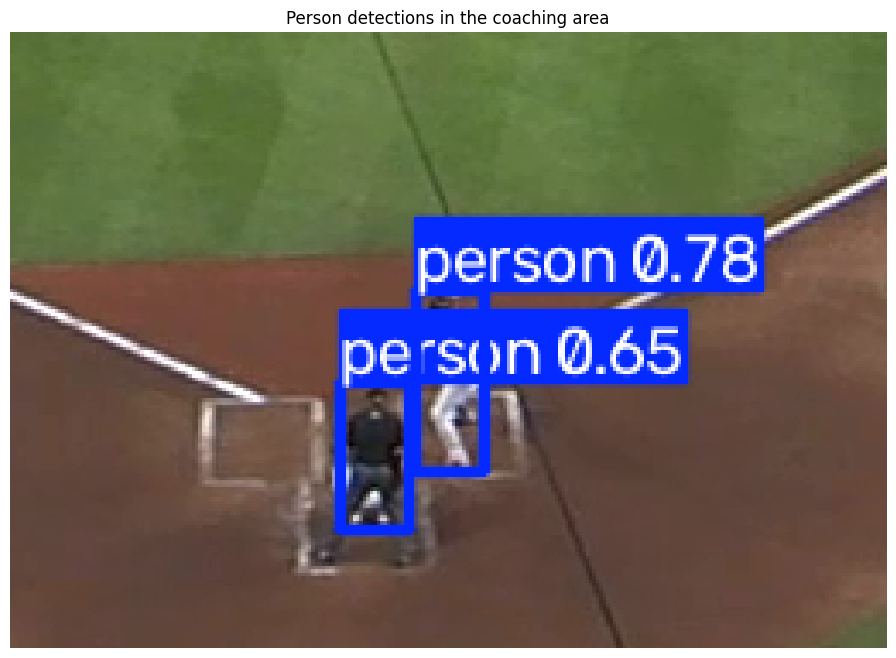

Detected 2 people
Person 0: confidence=0.781, crop_bbox=[118.39293670654297, 75.77449798583984, 138.10049438476562, 128.5951385498047]
Person 1: confidence=0.653, crop_bbox=[96.57657623291016, 102.1395492553711, 116.37886047363281, 145.5056915283203]


In [ ]:
# Detect People inside the crop
result = model.predict(
    source=roi,
    classes=[0],   # People only
    imgsz=960,
    conf=0.25,
    verbose=False
)[0]

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB))
plt.title("Person detections in the coaching area")
plt.axis("off")
plt.show()

print(f"Detected {len(result.boxes)} people")

for i, box in enumerate(result.boxes):
    bbox = box.xyxy[0].cpu().tolist()
    confidence = box.conf[0].item()
    print(f"Person {i}: confidence={confidence:.3f}, crop_bbox={bbox}")

Selected Person 0
Person-detection confidence: 0.781
Saved crop: coach_crops/pitch_clip_0.00s.png
Crop size: 74 × 80 pixels


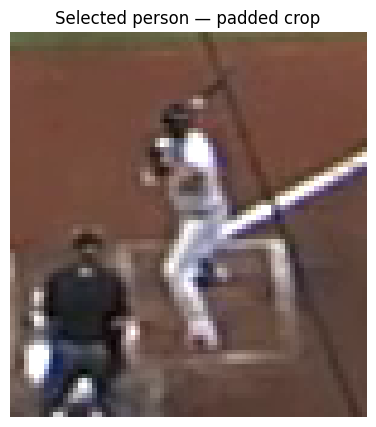

In [ ]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np

# --- Define missing identifiers (update these to match your clip) ---
pitch_id = "pitch_clip"  # or your video/pitch identifier
time_seconds = 0.0  # or the frame timestamp you are processing

# Expected batter/coach position in ORIGINAL-frame fractions.
expected_position = (0.55, 0.71)

frame_h, frame_w = frame.shape[:2]
roi_h, roi_w = roi.shape[:2]

# Convert expected position into crop coordinates (relative to the ROI origin [x1, y1]).
expected_center = np.array([
    expected_position[0] * frame_w - x1,
    expected_position[1] * frame_h - y1,
])

boxes = result.boxes.xyxy.cpu().numpy()
confidences = result.boxes.conf.cpu().numpy()

if len(boxes) == 0:
    print("No people detected. No crop saved.")
else:
    centers = (boxes[:, :2] + boxes[:, 2:]) / 2

    # Distance measured relative to original frame dimensions.
    distances = np.linalg.norm(
        (centers - expected_center) / np.array([frame_w, frame_h]), axis=1
    )

    coach_index = int(np.argmin(distances))

    # Guardrail threshold: tune if the subject moves across the clip.
    max_distance = 0.06

    if distances[coach_index] > max_distance:
        print("No person near the expected location. Review frame.")
    else:
        bx1, by1, bx2, by2 = boxes[coach_index]
        box_w = bx2 - bx1
        box_h = by2 - by1

        # Fixed syntax errors: added '*' for multiplication
        pad_x = max(box_w, 0.5 * box_h)
        pad_y = 0.25 * box_h

        cx1 = max(0, int(np.floor(bx1 - pad_x)))
        cy1 = max(0, int(np.floor(by1 - pad_y)))
        cx2 = min(roi_w, int(np.ceil(bx2 + pad_x)))
        cy2 = min(roi_h, int(np.ceil(by2 + pad_y)))

        coach_crop = roi[cy1:cy2, cx1:cx2].copy()

        output_dir = Path("coach_crops")
        output_dir.mkdir(exist_ok=True)
        output_path = output_dir / f"{pitch_id}_{time_seconds:.2f}s.png"

        if not cv2.imwrite(str(output_path), coach_crop):
            raise RuntimeError("Could not save crop.")

        print(f"Selected Person {coach_index}")
        print(f"Person-detection confidence: {confidences[coach_index]:.3f}")
        print(f"Saved crop: {output_path}")
        print(
            f"Crop size: {coach_crop.shape[1]} × {coach_crop.shape[0]} pixels"
        )

        plt.figure(figsize=(5, 5))
        plt.imshow(cv2.cvtColor(coach_crop, cv2.COLOR_BGR2RGB))
        plt.title("Selected person — padded crop")
        plt.axis("off")
        plt.show()

Using video: bkJva2RfWGxnR0RBeGJDMWM9X1Z3ZFlVbHdEQTFRQURBRlRVd0FBQ0FWVkFGaFFBZ01BQ2djTUF3cFRCRklCQVZjRg==.mp4
Total detections at plate: 2
Locked Batter Baseline: X=704.8px, Y=534.8px
Normalized Coordinates: (0.551, 0.743)


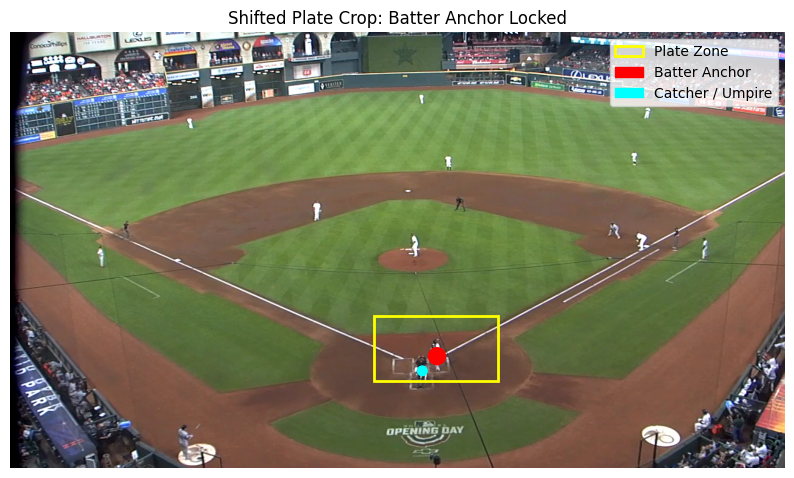

In [ ]:
# -------------------------------------------------------------
# STEP 1: DETECT AND LOCK BATTER (ROBUST LHB / RHB SELECTION)
# -------------------------------------------------------------
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle
import numpy as np
from ultralytics import YOLO

# 1. Initialize YOLO model
try:
    model
except NameError:
    model = YOLO("yolov8n.pt")

# 2. Locate video file
video_dir = Path("videos")
video_path = (
    video_dir
    / "bkJva2RfWGxnR0RBeGJDMWM9X1Z3ZFlVbHdEQTFRQURBRlRVd0FBQ0FWVkFGaFFBZ01BQ2djTUF3cFRCRklCQVZjRg==.mp4"
)

if not video_path.exists():
    mp4_files = list(video_dir.glob("*.mp4"))
    if mp4_files:
        video_path = mp4_files[0]
        print(f"Target file not found, defaulting to: {video_path}")
    else:
        raise FileNotFoundError(f"No .mp4 files found in {video_dir.resolve()}.")

# 3. Plate region: top at 0.51 to ensure batter's full body is included
plate_region = (0.47, 0.65, 0.63, 0.80)

cap = cv2.VideoCapture(str(video_path))
if not cap.isOpened():
    raise RuntimeError(f"Could not open {video_path}")

fps = cap.get(cv2.CAP_PROP_FPS) or 30.0

# Sample 0.6s into clip
cap.set(cv2.CAP_PROP_POS_MSEC, 600)
ok, init_frame = cap.read()
if not ok:
    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
    ok, init_frame = cap.read()

if not ok or init_frame is None:
    cap.release()
    raise RuntimeError("Failed to read video frames.")

h, w = init_frame.shape[:2]
px1, py1 = int(plate_region[0] * w), int(plate_region[1] * h)
px2, py2 = int(plate_region[2] * w), int(plate_region[3] * h)

plate_crop = init_frame[py1:py2, px1:px2].copy()

# Run YOLO detection for persons (class 0)
plate_res = model.predict(
    source=plate_crop, classes=[0], conf=0.15, verbose=False
)[0]
p_boxes = plate_res.boxes.xyxy.cpu().numpy()

if len(p_boxes) == 0:
    cap.release()
    raise RuntimeError("No players detected. Check plate_region bounds.")

full_p_boxes = []
for b in p_boxes:
    bx1, by1, bx2, by2 = b
    full_p_boxes.append([bx1 + px1, by1 + py1, bx2 + px1, by2 + py1])

full_p_boxes = np.array(full_p_boxes)
p_centers = (full_p_boxes[:, :2] + full_p_boxes[:, 2:]) / 2

# -------------------------------------------------------------
# ROBUST BATTER IDENTIFICATION:
# 1. Catcher & Umpire crouch furthest back (highest y in image space).
# 2. Batter stands further forward toward the pitcher (lower y in image space).
# 3. If multiple people are detected, the catcher/umpire line is estimated
#    from the lowest/deepest person, and the batter is the person elevated (lower y)
#    and laterally separated from that baseline.
# -------------------------------------------------------------
if len(p_boxes) == 1:
    batter_idx = 0
else:
    # Anchor point: lowest center in image space is the catcher/umpire position
    deepest_idx = int(np.argmax(p_centers[:, 1]))
    catcher_center_x = p_centers[deepest_idx, 0]

    # Batter is standing further forward (smaller y) and offset along x
    y_elevation = np.max(p_centers[:, 1]) - p_centers[:, 1]
    lateral_offset = np.abs(p_centers[:, 0] - catcher_center_x)

    # Combined score prioritizing higher position in frame + lateral separation
    scores = y_elevation * 1.5 + lateral_offset
    batter_idx = int(np.argmax(scores))

batter_start_x, batter_start_y = p_centers[batter_idx]

print(f"Using video: {video_path.name}")
print(f"Total detections at plate: {len(p_boxes)}")
print(f"Locked Batter Baseline: X={batter_start_x:.1f}px, Y={batter_start_y:.1f}px")
print(f"Normalized Coordinates: ({batter_start_x / w:.3f}, {batter_start_y / h:.3f})")

# Visual verification plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(cv2.cvtColor(init_frame, cv2.COLOR_BGR2RGB))
ax.add_patch(
    Rectangle(
        (px1, py1),
        px2 - px1,
        py2 - py1,
        fill=False,
        edgecolor="yellow",
        linewidth=2,
        label="Plate Zone",
    )
)

for i, center in enumerate(p_centers):
    if i == batter_idx:
        ax.add_patch(
            Circle(
                (center[0], center[1]),
                radius=14,
                color="red",
                label="Batter Anchor",
            )
        )
    else:
        ax.add_patch(
            Circle(
                (center[0], center[1]),
                radius=8,
                color="cyan",
                label="Catcher / Umpire" if i != batter_idx else "",
            )
        )

# Remove duplicate labels from legend
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc="upper right")

ax.set_title("Shifted Plate Crop: Batter Anchor Locked")
ax.axis("off")
plt.show()

cap.release()

Monitoring Batter on screen-RIGHT (excluding catcher/umpire)...
--> BATTER SPRINT CONFIRMED at frame 281 (4.70s)!
    Displacement: 42.9px


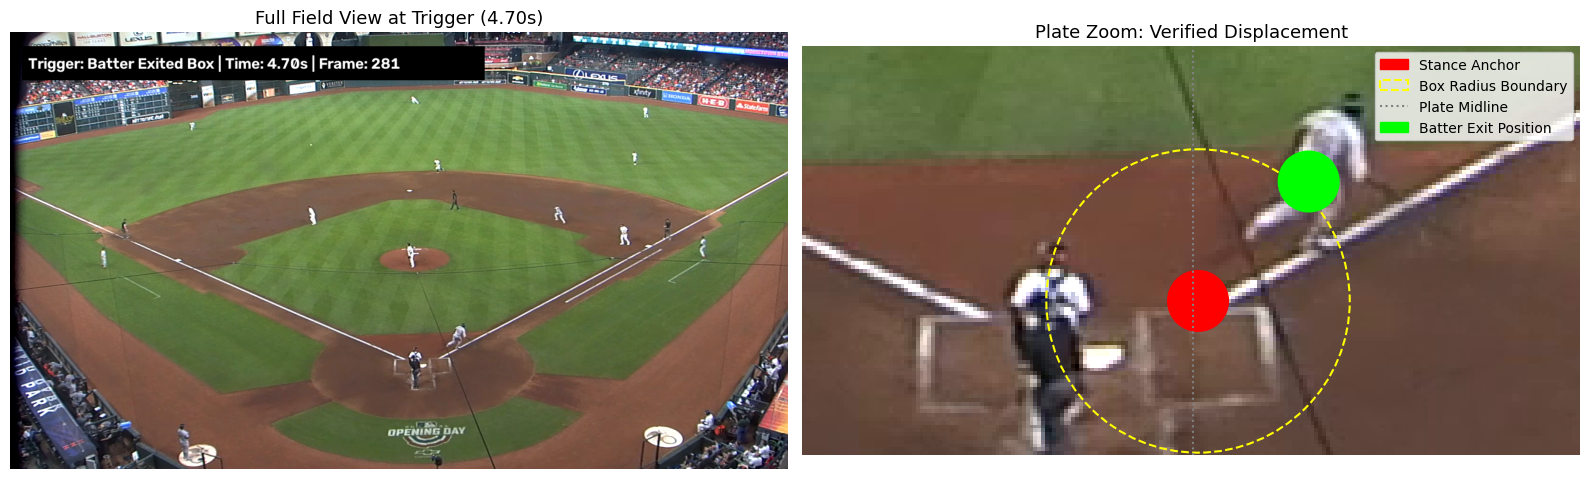

In [ ]:
# -------------------------------------------------------------
# STEP 2: ISOLATED BATTER EXIT DETECTION (IGNORES CATCHER & UMPIRE)
# -------------------------------------------------------------
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle
import numpy as np

# Re-open capture fresh
if "cap" in locals() and cap is not None:
    cap.release()
if "video_path" in locals():
    cap = cv2.VideoCapture(str(video_path))
else:
    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS) or 30.0

# -----------------------------------------------------------------
# 1. DEFINE BATTER SIDE & EXCLUSION ZONE
# -----------------------------------------------------------------
# Identify if batter is in Left-hand or Right-hand batter's box
# Note: In standard baseball broadcast view:
# - Left of screen = 3rd base side / Right-handed batter's box
# - Right of screen = 1st base side / Left-handed batter's box
is_screen_left = batter_start_x < plate_center_x

# Plate Y reference: catcher and umpire are located deeper (larger Y)
# We exclude detections that are centered along the plate midline or deep behind home
MIDLINE_BUFFER = 18.0  # Pixels away from center line
BATTER_BOX_RADIUS = 40.0
FRAME_STEP = 2
CONSECUTIVE_EXITS = 2

# Start scanning near pitch release (around 2.0s)
MIN_START_TIME_SEC = 2.0
min_trigger_frame = int(MIN_START_TIME_SEC * fps)

frame_idx = 0
trigger_frame = None
trigger_time_sec = None
trigger_frame_img = None
trigger_batter_pos = None

consecutive_exits = 0
batter_confirmed_in_box = False
last_known_pos = np.array([batter_start_x, batter_start_y], dtype=float)

print(f"Monitoring Batter on screen-{'LEFT' if is_screen_left else 'RIGHT'} (excluding catcher/umpire)...")

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    if frame_idx < min_trigger_frame:
        frame_idx += 1
        continue

    if (frame_idx - min_trigger_frame) % FRAME_STEP != 0:
        frame_idx += 1
        continue

    plate_crop = frame[py1:py2, px1:px2]

    res = model.predict(source=plate_crop, classes=[0], conf=0.18, imgsz=320, verbose=False)[0]
    boxes = res.boxes.xyxy.cpu().numpy()

    detected_batter_pos = None
    shift_from_anchor = 0.0

    valid_batter_candidates = []

    if len(boxes) > 0:
        centers = (boxes[:, :2] + boxes[:, 2:]) / 2
        centers[:, 0] += px1
        centers[:, 1] += py1

        for pt in centers:
            x_dist_from_midline = pt[0] - plate_center_x

            # Filter OUT Catcher & Umpire:
            # Catcher/umpire stay centered on plate or directly behind plate
            # The batter is clearly displaced to the left or right of the midline
            if abs(x_dist_from_midline) < MIDLINE_BUFFER and pt[1] >= (plate_center_y if 'plate_center_y' in locals() else batter_start_y):
                continue  # Skip catcher / umpire!

            # Check if candidate matches batter stance side or has started running to 1st base (screen right)
            if is_screen_left:
                # If RHB: stance is left, running path heads across/right toward 1st base
                valid_batter_candidates.append(pt)
            else:
                # If LHB: stance is right, running path continues down the right baseline
                if x_dist_from_midline > 0:
                    valid_batter_candidates.append(pt)

    if len(valid_batter_candidates) > 0:
        valid_batter_candidates = np.array(valid_batter_candidates)

        # Match the closest detection to the batter's stance / last position
        dists = np.linalg.norm(valid_batter_candidates - last_known_pos, axis=1)
        best_idx = int(np.argmin(dists))
        detected_batter_pos = valid_batter_candidates[best_idx]

        shift_from_anchor = np.linalg.norm(detected_batter_pos - np.array([batter_start_x, batter_start_y]))

        if shift_from_anchor <= BATTER_BOX_RADIUS:
            batter_confirmed_in_box = True
            last_known_pos = detected_batter_pos
            consecutive_exits = 0
        else:
            # If the batter was confirmed in box and now displaces past the radius
            if batter_confirmed_in_box:
                consecutive_exits += 1
                last_known_pos = detected_batter_pos

    # If the batter sprints completely out of the tight plate crop zone
    elif batter_confirmed_in_box and consecutive_exits > 0:
        consecutive_exits += 1

    # Confirm exit trigger
    if consecutive_exits >= CONSECUTIVE_EXITS:
        trigger_frame = frame_idx
        trigger_time_sec = trigger_frame / fps
        trigger_frame_img = frame.copy()
        trigger_batter_pos = detected_batter_pos
        print(f"--> BATTER SPRINT CONFIRMED at frame {trigger_frame} ({trigger_time_sec:.2f}s)!")
        print(f"    Displacement: {shift_from_anchor:.1f}px")
        break

    frame_idx += 1

cap.release()

if trigger_frame is None:
    raise RuntimeError("Batter was never confirmed leaving the box. Check Step 1 batter_start coordinates.")

# -------------------------------------------------------------
# DISPLAY RESULTS
# -------------------------------------------------------------
output_dir = Path("trigger_event")
output_dir.mkdir(exist_ok=True)

annotated_img = trigger_frame_img.copy()
overlay_text = f"Trigger: Batter Exited Box | Time: {trigger_time_sec:.2f}s | Frame: {trigger_frame}"
cv2.rectangle(annotated_img, (20, 25), (780, 80), (0, 0, 0), -1)
cv2.putText(annotated_img, overlay_text, (30, 62), cv2.FONT_HERSHEY_SIMPLEX, 0.85, (255, 255, 255), 2, cv2.LINE_AA)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Full Field View at Trigger ({trigger_time_sec:.2f}s)", fontsize=13)
axes[0].axis("off")

zoom_crop = annotated_img[py1:py2, px1:px2].copy()
axes[1].imshow(cv2.cvtColor(zoom_crop, cv2.COLOR_BGR2RGB))

crop_anchor_x = batter_start_x - px1
crop_anchor_y = batter_start_y - py1
axes[1].add_patch(Circle((crop_anchor_x, crop_anchor_y), radius=8, color="red", label="Stance Anchor"))
axes[1].add_patch(Circle((crop_anchor_x, crop_anchor_y), radius=BATTER_BOX_RADIUS, fill=False, edgecolor="yellow", linestyle="--", linewidth=1.5, label="Box Radius Boundary"))
axes[1].axvline(plate_center_x - px1, color="gray", linestyle=":", linewidth=1.5, label="Plate Midline")

if trigger_batter_pos is not None:
    crop_exit_x = trigger_batter_pos[0] - px1
    crop_exit_y = trigger_batter_pos[1] - py1
    axes[1].add_patch(Circle((crop_exit_x, crop_exit_y), radius=8, color="lime", label="Batter Exit Position"))

axes[1].legend(loc="upper right")
axes[1].set_title("Plate Zoom: Verified Displacement", fontsize=13)
axes[1].axis("off")

plt.tight_layout()
plt.show()